# 05 · Feature Selection

**The question:** Of the 45 available features (42 original + 3 engineered), which should we carry forward to the models?

| | |
|---|---|
| **Input** | Raw training rows, roles (Notebook 02), engineered columns and model inputs (Notebooks 03 and 04) |
| **What we do** | Check every feature for copies, near-copies, low variation and usefulness, then make a clear decision |
| **Output** | Two feature sets for Notebook 06 (the original 42, and the selected 44) with ready model inputs for every role |

### What is feature selection?

**Feature selection means deciding which columns the model should use.** Removing a column can help if it is a copy of another column,
never changes, or carries no information. Removing a useful column hurts. So we look at the evidence for each feature first.

Everything here uses the **`train` rows only**. We do not look at model scores yet. That is Notebook 06's job.

### Our decision rules (written down before looking at the results)

1. **Original 42 columns:** these are real measurements. We remove one only if it is an exact copy in *all* data, or carries no information at all.
   Being correlated with another column is **not** enough: tree models handle that well, and small differences can matter for rare classes.
2. **Engineered columns:** these are optional extras. We keep one only if it is not a near-copy of another engineered column.
   If two engineered columns are near-copies, we keep the one with the higher usefulness score (section 6).
3. **The original 42 always stay available as the reference set**, so we can measure whether the extras help.

## 1. Setup and load the train rows with all 45 features

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import GroupKFold

from src.notebook_helpers import (ROOT, TRAIN_CSV, TEST_CSV, RAW_SHA256, TARGETS, CATEGORICAL, CLASSES, ROLES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style)
setup_style()

assert sha256(TRAIN_CSV) == RAW_SHA256['train']
raw = pd.read_csv(TRAIN_CSV, low_memory=False)
roles = pd.read_csv(DATA / '02_roles.csv')
raw['role'] = roles.role.to_numpy()
raw['pattern'] = roles.pattern.to_numpy()

ORIGINAL = [c for c in pd.read_csv(TRAIN_CSV, nrows=0).columns if c not in TARGETS]
NEW = ['fe_total_bytes', 'fe_byte_balance', 'fe_packet_balance']
fit = raw[raw.role == 'train'].copy()
engineered = pd.read_csv(DATA / '04_engineered_train.csv')
assert (engineered.row_position.to_numpy() == np.flatnonzero(raw.role == 'train')).all()
fit[NEW] = engineered[NEW].to_numpy()
ALL = ORIGINAL + NEW
numeric_all = [c for c in ALL if c not in CATEGORICAL]
print(f'train rows: {len(fit):,} | candidate features: {len(ALL)} ({len(ORIGINAL)} original + {len(NEW)} engineered)')

train rows: 140,273 | candidate features: 45 (42 original + 3 engineered)


## 2. Check 1: exact copies

Is any feature exactly equal to another feature in every train row?

In [2]:
copies = []
for i, a in enumerate(numeric_all):
    for b in numeric_all[i + 1:]:
        if (fit[a] == fit[b]).all():
            copies.append((a, b))
print('Exact copies in the train rows:', copies)

test = pd.read_csv(TEST_CSV, low_memory=False)
for a, b in copies:
    print(f'  {a} vs {b}: different in {(raw[a] != raw[b]).sum()} rows of the full training file '
          f'and in {(test[a] != test[b]).sum()} rows of the test file')
del test

Exact copies in the train rows: [('is_ftp_login', 'ct_ftp_cmd')]


  is_ftp_login vs ct_ftp_cmd: different in 0 rows of the full training file and in 8 rows of the test file


**What we see:** `is_ftp_login` and `ct_ftp_cmd` are identical in every training row, but **not** in the test file (8 rows differ).
They are not true copies, just copies in this sample. Both are almost always 0 anyway (98.5% of rows).

**Decision:** keep both (rule 1: not a copy in *all* data). Removing one would throw away the rows where they disagree.

## 3. Check 2: near-copies

Pairs with a Spearman correlation of 0.95 or more carry nearly the same information.

In [3]:
corr = fit[numeric_all].corr(method='spearman')
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
near = upper[upper.abs() >= 0.95].sort_values(key=abs, ascending=False).rename('spearman').reset_index()
near.columns = ['feature A', 'feature B', 'spearman']
near['involves engineered'] = near['feature A'].isin(NEW) | near['feature B'].isin(NEW)
save_table(near, '05_near_copies')
display(near)

,feature A,feature B,spearman,involves engineered
0,is_ftp_login,ct_ftp_cmd,1.0000,False
1,trans_depth,ct_flw_http_mthd,0.9996,False
2,tcprtt,synack,0.9968,False
3,tcprtt,ackdat,0.9937,False
4,swin,dwin,0.9905,False
5,dpkts,dbytes,0.9897,False
6,synack,ackdat,0.9844,False
7,dmean,fe_byte_balance,-0.9753,True
8,fe_byte_balance,fe_packet_balance,0.9734,True
9,sbytes,fe_total_bytes,0.9647,True


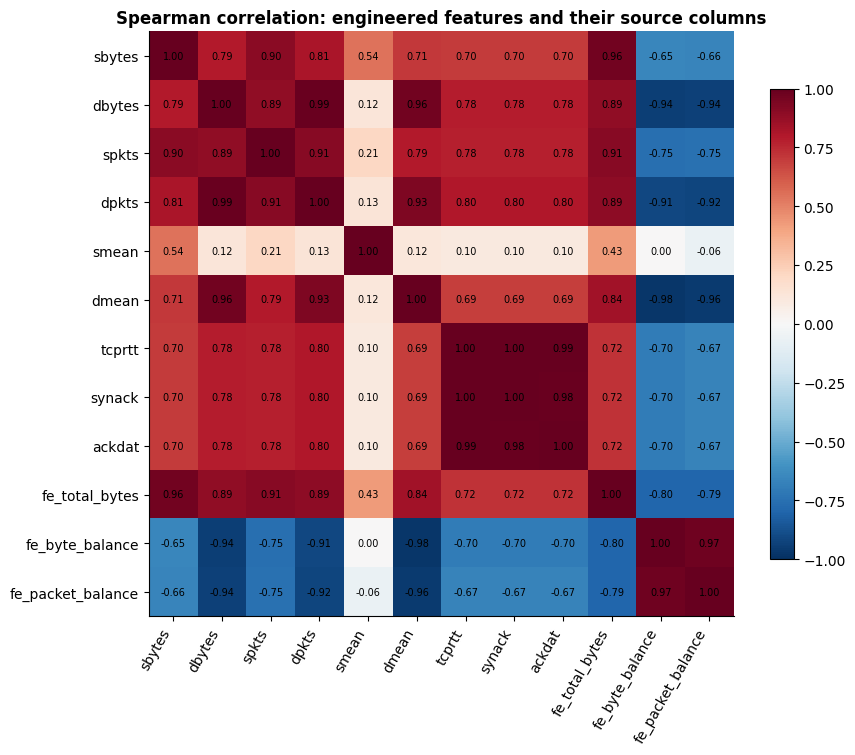

In [4]:
show = ['sbytes', 'dbytes', 'spkts', 'dpkts', 'smean', 'dmean', 'tcprtt', 'synack', 'ackdat'] + NEW
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.loc[show, show], cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(show)), show, rotation=60, ha='right'); ax.set_yticks(range(len(show)), show); ax.grid(False)
for i in range(len(show)):
    for j in range(len(show)):
        ax.text(j, i, f'{corr.loc[show[i], show[j]]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title('Spearman correlation: engineered features and their source columns')
plt.tight_layout(); save_figure(fig, '05_engineered_correlations'); plt.show()

**What we see:**

- Among the original columns, near-copies are pairs like `tcprtt`/`synack`/`ackdat` and `trans_depth`/`ct_flw_http_mthd`.
  They are separate measurements (for example `tcprtt = synack + ackdat`), so by rule 1 we **keep them all**.
- Among the engineered columns, **byte balance and packet balance are near-copies (0.97)**. By rule 2 only one of them should stay.
  Section 6 decides which.
- Byte balance is also a near-copy of `dmean` in ranking (-0.98) because of the many "no reply" flows (Notebook 04).
  It is still kept as a candidate: `dmean` is an original column and the balance expresses direction on a fixed -1 to +1 scale.

## 4. Check 3: features that hardly change

A feature that has the same value in almost every row gives a model little to work with. But a rare value can still be very
important if it marks a rare class, so we look at that too.

In [5]:
variation = pd.DataFrame({
    'most common value': fit[ALL].mode().iloc[0],
    '% rows with that value': [fit[c].value_counts(normalize=True).iloc[0] * 100 for c in ALL],
    'distinct values': fit[ALL].nunique(),
}).sort_values('% rows with that value', ascending=False)
save_table(variation, '05_variation', index=True)
display(variation.head(8))

rare_flags = ['is_sm_ips_ports', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'trans_depth']
display((fit[rare_flags].ne(0).groupby(fit.attack_cat).mean() * 100).reindex(CLASSES).round(1)
        .T.rename_axis('% of class rows where the value is not 0'))

,most common value,% rows with that value,distinct values
ct_ftp_cmd,0,98.5450,4
is_ftp_login,0,98.5450,4
is_sm_ips_ports,0,98.4238,2
response_body_len,0,93.5084,2100
trans_depth,0,89.7928,11
ct_flw_http_mthd,0,89.7928,11
sttl,254,65.3811,10
ct_dst_sport_ltm,1,62.5502,31


attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
% of class rows where the value is not 0,,,,,,,,,,
is_sm_ips_ports,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.9000,0.0000,0.0000,0.0000
is_ftp_login,0.0000,0.0000,0.1000,4.4000,0.7000,0.0000,1.7000,0.0000,0.0000,0.0000
ct_ftp_cmd,0.0000,0.0000,0.1000,4.4000,0.7000,0.0000,1.7000,0.0000,0.0000,0.0000
ct_flw_http_mthd,27.9000,4.4000,9.3000,24.0000,5.7000,0.8000,9.3000,14.2000,0.0000,77.9000
trans_depth,27.9000,4.4000,9.3000,24.0000,5.7000,0.8000,9.3000,14.2000,0.0000,77.9000


**What we see:** No feature is constant. Five features are almost always 0, but their non-zero values are concentrated in particular
classes: the HTTP counters are non-zero for **78% of Worms** rows, the FTP fields mostly for Exploits, and `is_sm_ips_ports` only for Normal.
Rare values like these are exactly what helps with rare classes.

**Decision:** keep all of them.

## 5. How we measure usefulness: mutual information

**Mutual information (MI)** measures how much knowing a feature reduces our uncertainty about the class. 0 means "tells us nothing";
higher means "more informative". It captures any kind of relationship, not only straight lines.

To calculate it for number columns, we first put the values into 20 equal-sized bins (tied values always stay in the same bin).

**A fair calculation:** remember that many rows are repeats (Notebook 02). We split the train rows into **3 groups by pattern**
(identical rows always in the same group) and compute MI separately in each. If a feature's score is similar in all three, the result is stable.

In [6]:
def to_bins(values):
    if values.dtype.kind in 'fi' and values.nunique() > 20:
        return pd.qcut(values, 20, labels=False, duplicates='drop')
    return values


folds = GroupKFold(n_splits=3).split(fit, groups=fit.pattern)
mi = {}
for k, (_, rows) in enumerate(folds, start=1):
    part = fit.iloc[rows]
    mi[f'fold {k}'] = {c: mutual_info_score(part.attack_cat, to_bins(part[c])) for c in ALL}
mi = pd.DataFrame(mi)
mi['mean'] = mi.mean(axis=1)
mi['spread (std)'] = mi[['fold 1', 'fold 2', 'fold 3']].std(axis=1)
mi = mi.sort_values('mean', ascending=False)
mi['rank'] = np.arange(1, len(mi) + 1)
save_table(mi, '05_mutual_information', index=True)
display(mi.head(12))

,fold 1,fold 2,fold 3,mean,spread (std),rank
sbytes,0.6820,0.6767,0.6845,0.6810,0.0040,1
fe_total_bytes,0.6807,0.6692,0.6789,0.6763,0.0062,2
smean,0.6396,0.6533,0.6616,0.6515,0.0111,3
sload,0.5517,0.5416,0.5381,0.5438,0.0071,4
dttl,0.4946,0.4882,0.4915,0.4915,0.0032,5
ct_state_ttl,0.4935,0.4855,0.4928,0.4906,0.0045,6
service,0.4870,0.4847,0.4789,0.4835,0.0042,7
ct_dst_sport_ltm,0.4846,0.4907,0.4716,0.4823,0.0097,8
proto,0.4854,0.4792,0.4696,0.4781,0.0080,9
sttl,0.4681,0.4679,0.4709,0.4690,0.0017,10


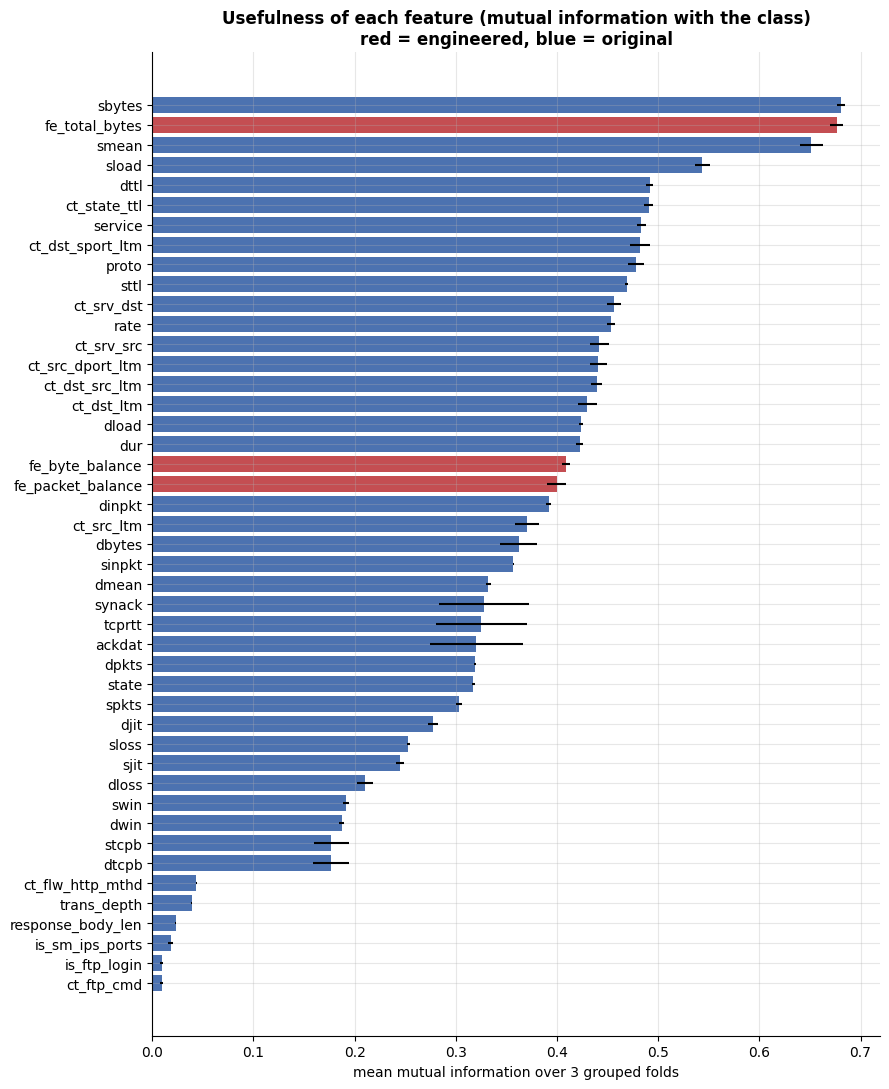

In [7]:
fig, ax = plt.subplots(figsize=(9, 11))
colors = ['#C44E52' if c in NEW else '#4C72B0' for c in mi.index]
ax.barh(mi.index[::-1], mi['mean'][::-1], xerr=mi['spread (std)'][::-1], color=colors[::-1])
ax.set(title='Usefulness of each feature (mutual information with the class)\nred = engineered, blue = original',
       xlabel='mean mutual information over 3 grouped folds')
plt.tight_layout(); save_figure(fig, '05_mutual_information'); plt.show()

**What we see:**

- The most informative features are the **sizes** (`sbytes`, `fe_total_bytes`, `smean`), followed by load, TTL, service and protocol.
- **`fe_total_bytes` ranks second of 45**, just behind `sbytes`. The two balances sit in the middle of the list.
- The scores are almost the same in all three folds, so the ranking is stable.
- The least informative features (FTP and HTTP counters, `is_sm_ips_ports`) are the rare-value features from section 4. They are weak *on average*,
  but carry information for a few rare classes, so we keep them.

**Careful:** MI looks at one feature at a time. A feature with low MI can still be useful in combination with others, and a high MI does not prove
a model will improve. That proof can only come from the models in Notebook 06.

## 6. Decision: which balance to keep?

Rule 2 says: keep the engineered near-copy with the higher usefulness score.

In [8]:
balances = mi.loc[['fe_byte_balance', 'fe_packet_balance'], ['fold 1', 'fold 2', 'fold 3', 'mean', 'rank']]
display(balances)
wins = (balances.loc['fe_byte_balance', ['fold 1', 'fold 2', 'fold 3']] > balances.loc['fe_packet_balance', ['fold 1', 'fold 2', 'fold 3']]).sum()
KEEP_BALANCE = balances['mean'].idxmax()
DROP_BALANCE = balances['mean'].idxmin()
print(f'Byte balance scores higher in {wins} of 3 folds. Keep: {KEEP_BALANCE}. Drop: {DROP_BALANCE}.')

,fold 1,fold 2,fold 3,mean,rank
fe_byte_balance,0.4134,0.4047,0.4087,0.4089,19
fe_packet_balance,0.4084,0.3894,0.4010,0.3996,20


Byte balance scores higher in 3 of 3 folds. Keep: fe_byte_balance. Drop: fe_packet_balance.


**Decision:** keep **byte balance** and drop **packet balance**. The difference is small, but it points the same way in every fold.
Byte balance is also easier to interpret: it describes how much *data* moved in each direction.

## 7. The final decision

| Feature(s) | Decision | Reason |
|---|---|---|
| All 42 original columns | **Keep** | Real measurements; no copy in all data, none constant, rare-value ones help rare classes |
| `fe_total_bytes` | **Keep** | Ranks 2nd of 45 in usefulness; not a copy of any single column |
| `fe_byte_balance` | **Keep** | Expresses traffic direction; more useful than packet balance in every fold |
| `fe_packet_balance` | **Drop** | Near-copy of byte balance (0.97) and slightly less useful |

This gives **two feature sets** for Notebook 06:

- **`original42`**: the 42 original columns. This is the reference.
- **`total_and_byte44`**: the 42 original columns + total bytes + byte balance. This is our selected set.

Comparing these two with the same models answers one clear question: **do the engineered features help?**

In [9]:
SETS = {
    'original42': ORIGINAL,
    'total_and_byte44': ORIGINAL + ['fe_total_bytes', KEEP_BALANCE],
}
decision = pd.DataFrame([{'feature': c,
                          'kind': 'engineered' if c in NEW else 'original',
                          'in original42': c in SETS['original42'],
                          'in total_and_byte44': c in SETS['total_and_byte44'],
                          'MI rank (of 45)': int(mi.loc[c, 'rank'])} for c in ALL])
save_table(decision, '05_feature_decision')
display(decision[decision.kind == 'engineered'])
print({name: len(cols) for name, cols in SETS.items()})

,feature,kind,in original42,in total_and_byte44,MI rank (of 45)
42,fe_total_bytes,engineered,False,True,2
43,fe_byte_balance,engineered,False,True,19
44,fe_packet_balance,engineered,False,False,20


{'original42': 42, 'total_and_byte44': 44}


## 8. Build the model inputs for both sets

Notebook 04 already prepared the inputs with all 45 features (`tree` and `scaled` versions). Each set is simply a selection of those columns:
for `original42` we drop the 3 engineered columns, for `total_and_byte44` we drop only packet balance.
One-hot columns of a text feature always stay together.

In [10]:
names = read_json(MODELS / '04_feature_names.json')
inputs, columns = {}, {}
for version in ['tree', 'scaled']:
    all_names = names[version]
    for set_name, features in SETS.items():
        dropped = [f for f in NEW if f not in features]
        keep = [i for i, n in enumerate(all_names) if n not in dropped]
        columns[(set_name, version)] = [all_names[i] for i in keep]
        for role in ROLES:
            full = sparse.load_npz(DATA / f'04_{version}_plus3_{role}.npz')
            inputs[(set_name, version, role)] = full[:, keep].tocsr()

shapes = pd.DataFrame({(s, v): [inputs[(s, v, r)].shape for r in ROLES] for s in SETS for v in ['tree', 'scaled']}, index=ROLES)
display(shapes)

original42                total_and_byte44               
                          tree         scaled             tree         scaled
train            (140273, 193)  (140273, 193)    (140273, 195)  (140273, 195)
model_selection   (17534, 193)   (17534, 193)     (17534, 195)   (17534, 195)
calibration       (17534, 193)   (17534, 193)     (17534, 195)   (17534, 195)

### Checks

1. Every value is finite and the row order matches the roles file.
2. The inputs are identical to the ones the earlier project version saved for the same two sets (`data/processed/05/`),
   which Notebook 07 (the neural reference model) also uses.
3. No pattern is shared between roles: `original42` uses exactly the Notebook 02 grouping columns, and adding columns can only make rows *more* different.

In [11]:
check = []
for (set_name, version, role), x in inputs.items():
    old = sparse.load_npz(ROOT / f'data/processed/05/05_{set_name}_{version}_{role}.npz')
    check.append({'set': set_name, 'version': version, 'role': role, 'shape': x.shape,
                  'all finite': bool(np.isfinite(x.data).all()),
                  'identical to earlier inputs': bool(old.shape == x.shape and abs(old - x).max() < 1e-9)})
check = pd.DataFrame(check)
save_table(check, '05_checks')
display(check)
assert check['all finite'].all() and check['identical to earlier inputs'].all()

,set,version,role,shape,all finite,identical to earlier inputs
0,original42,tree,train,"(140273, 193)",True,True
1,original42,tree,model_selection,"(17534, 193)",True,True
2,original42,tree,calibration,"(17534, 193)",True,True
3,total_and_byte44,tree,train,"(140273, 195)",True,True
4,total_and_byte44,tree,model_selection,"(17534, 195)",True,True
5,total_and_byte44,tree,calibration,"(17534, 195)",True,True
6,original42,scaled,train,"(140273, 193)",True,True
7,original42,scaled,model_selection,"(17534, 193)",True,True
8,original42,scaled,calibration,"(17534, 193)",True,True
9,total_and_byte44,scaled,train,"(140273, 195)",True,True


## 9. Save

In [12]:
for (set_name, version, role), x in inputs.items():
    sparse.save_npz(DATA / f'05_{set_name}_{version}_{role}.npz', x)
save_json({'sets': SETS, 'columns': {f'{s}/{v}': c for (s, v), c in columns.items()},
           'dropped': [DROP_BALANCE], 'rules': ['keep original columns unless copy in all data or no information',
                                                'keep engineered column unless near-copy of a more useful engineered column']},
          MODELS / '05_feature_sets.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved', len(inputs), 'input matrices and the feature-set definition. Raw file unchanged.')

Saved 12 input matrices and the feature-set definition. Raw file unchanged.


## Summary

### What we decided

| | Features | Why |
|---|---|---|
| **Kept** | all 42 original + `fe_total_bytes` + `fe_byte_balance` | real measurements, or engineered features with a clear purpose |
| **Dropped** | `fe_packet_balance` | near-copy of byte balance (Spearman 0.97) and slightly less informative in every fold |

Two sets go to Notebook 06: **`original42`** (reference) and **`total_and_byte44`** (selected).

### What we learned on the way

- The only exact copy (`is_ftp_login` = `ct_ftp_cmd`) holds in training but not in testing, so both stay.
- Size features are the most informative; `fe_total_bytes` ranks 2nd of 45.
- Weak-on-average features (FTP/HTTP flags) matter for rare classes such as Worms.

### What is still uncertain

- Mutual information judges one feature at a time. Only a model comparison can show whether the two extra features improve detection.

### What Notebook 06 does next

Train **baseline models** (logistic regression, decision tree, LightGBM) on both sets with identical settings, compare them on the
`model_selection` rows, and answer: **do the engineered features help, and which baseline is strongest?**